<a href="https://colab.research.google.com/github/keudithmanco-gif/Material-de-Analitica-de-Negocios-UDEA/blob/main/M3_S7_SQL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# <font color='056938'> **Caso de estudio** </font>
---
Considere la información de la Tienda de informatica

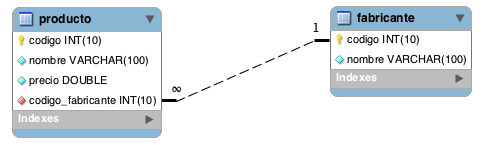

A continuación se utilizarán cláusulas y funciones para responder a preguntas de interés sobre las dos tablas usadas en la Tienda de Informática. Las líneas de código presentadas en este notebook funcionan para SQL Lite y se pueden ejecutar en [SQL Online IDE](https://sqliteonline.com/).

# <font color='056938'> **1. Creación de tablas** </font>
---
A continuación se crearán dos tablas denominadas fabricante y poducto. En la primera tabla, fabricante, se define el id como un entero (INT), no negativo (UNSIGNED), generado automaticamente de forma incremental (AUTO_INCREMENT) y siendo este id la clave primaria (PRIMARY KEY) con la que se relaciona con la segunda tabla producto. Además, se define el nombre del fabricante (nombre) como un string de tamaño 100 (VARCHAR(100)) y no nulo (NOT NULL).

En la segunda tabla, producto, se define el id como un entero (INT), no negativo (UNSIGNED), gereado automaticamente de forma incremental (AUTO_INCREMENT) y siendo este id la clave primaria (PRIMARY KEY). Además, se define el nombre del producto (nombre) como un string de tamaño 100 (VARCHAR(100)) y no nulo (NOT NULL), el precio como valor numérico (DOUBLE) no nulo (NOT NULL) y el id_fabricante como un entero (INT), no negativo (UNSIGNED) y no nulo (NOT NULL). Por último, se define la clave secundaria (FOREIGN KEY) que relacionará esta tabla de producto con la de fabricante.
```
CREATE TABLE fabricante (
  id INT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
  nombre VARCHAR(100) NOT NULL
);

CREATE TABLE producto (
  id INT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
  nombre VARCHAR(100) NOT NULL,
  precio DOUBLE NOT NULL,
  id_fabricante INT UNSIGNED NOT NULL,
  FOREIGN KEY (id_fabricante) REFERENCES fabricante(id)
);
```

# <font color='056938'> **2. Ingreso de valores** </font>
---
A continuación se ingresarán valores a cada una de las tablas, fabricante y producto.

```
INSERT INTO fabricante VALUES(1, 'Asus');
INSERT INTO fabricante VALUES(2, 'Lenovo');
INSERT INTO fabricante VALUES(3, 'Hewlett-Packard');
INSERT INTO fabricante VALUES(4, 'Samsung');
INSERT INTO fabricante VALUES(5, 'Seagate');
INSERT INTO fabricante VALUES(6, 'Crucial');
INSERT INTO fabricante VALUES(7, 'Gigabyte');
INSERT INTO fabricante VALUES(8, 'Huawei');
INSERT INTO fabricante VALUES(9, 'Xiaomi');

INSERT INTO producto VALUES(1, 'Disco duro SATA3 1TB', 86.99, 5);
INSERT INTO producto VALUES(2, 'Memoria RAM DDR4 8GB', 120, 6);
INSERT INTO producto VALUES(3, 'Disco SSD 1 TB', 150.99, 4);
INSERT INTO producto VALUES(4, 'GeForce GTX 1050Ti', 185, 7);
INSERT INTO producto VALUES(5, 'GeForce GTX 1080 Xtreme', 755, 6);
INSERT INTO producto VALUES(6, 'Monitor 24 LED Full HD', 202, 1);
INSERT INTO producto VALUES(7, 'Monitor 27 LED Full HD', 245.99, 1);
INSERT INTO producto VALUES(8, 'Portátil Yoga 520', 559, 2);
INSERT INTO producto VALUES(9, 'Portátil Ideapd 320', 444, 2);
INSERT INTO producto VALUES(10, 'Impresora HP Deskjet 3720', 59.99, 3);
INSERT INTO producto VALUES(11, 'Impresora HP Laserjet Pro M26nw', 180, 3);
```

# <font color='056938'> **3. Consultas básicas de una tabla** </font>
---
A continuación se usarán las cláusulas SELECT, ORDER BY, LIMIT y WHERE.

# <font color='056938'> **3.1 Sintaxis de la cláusula SELECT** </font>
---
La sintaxis para realizar una consulta sencila con la sentencia
SELECT es la siguiente

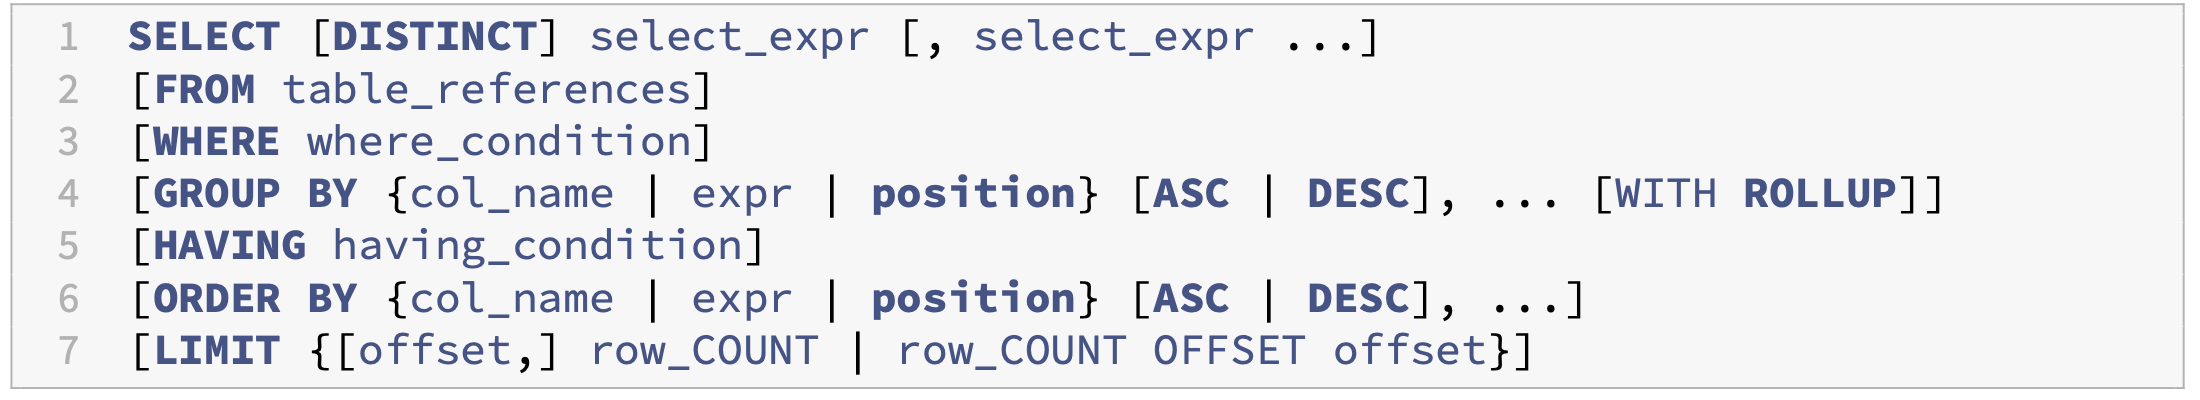

El orden en que se ejecuta cada una de las cláusulas es la siguiente:

*   Cláusula FROM
*   Cláusula WHERE (Opcional)
*   Cláusula GROUP BY (opcional)
*   Cláusula HAVING (Opcional)
*   Cláusula ORDER BY (Opcional)
*   Cláusula LIMIT (Opcional)

NOTA: Hay que tener en cuenta que el resultado de una consulta siempre será una tabla de datos, que puede tener una o varias columnas y ninguna, una o varias filas. El hecho de que el resultado de una consulta sea una tabla es muy interesante porque nos permite realizar cosas como almacenar los resultados como una nueva en la base de datos. También será posible combinar el resultado de dos o más consultas para crear una tabla mayor con la unión de los dos resultados. Además, los resultados de una consulta también pueden consultados por otras nuevas consultas.

# <font color='056938'> **3.2 Cláusula SELECT** </font>
---
Esta cláusula permite indicar cuáles serán las columnas que tendrá la tabla de resultados de la consulta que se esta realizando. Las opciones que se pueden indicar son las siguientes:

*   El **nombre de una columna** de la tabla sobre la que se esta realizando la consulta. Será una columna de la tabla que aparece en la cláusula FROM.
*   Una **constante** que aparecerá en todas las filas de la tabla resultado.
*   Una expresión que nos permite calcular nuevos valores.

## <font color='157699'> **Cómo listar una columna de una tabla** </font>
**Ejemplo**: Lista el nombre de todos los productos que hay en la tabla producto.

```
SELECT nombre
FROM producto;
```


## <font color='157699'> **Cómo listar varias columnas de una tabla** </font>
**Ejemplo**: Lista los nombres y los precios de todos los productos de la tabla producto.
```
SELECT nombre, precio
FROM producto;
```
NOTA: Tenga en cuenta que el resultado de la consulta SQL mostrará las columnas que haya solicitado, siguiendo el orden en el que se hayan indicado.

## <font color='157699'> **Cómo listar todas las columnas de una tabla** </font>
**Ejemplo**: Lista todas las columnas de la tabla producto.
```
SELECT *
FROM producto;
```
NOTAS:

1.   El carácter * es un comodín que utilizamos para indicar que queremos
seleccionar todas las columnas de la tabla. La consulta anterior devolverá todos los datos de la tabla producto.

2.   Otra consideración que también debemos tener en cuenta es que una consulta SQL se puede escribir en una o varias líneas. Por ejemplo, la siguiente sentencia tendría el mismo resultado que la anterior:

```
SELECT * FROM producto;
```

## <font color='157699'> **Cómo cobtener columnas calculadas** </font>
**Ejemplo**: Lista el nombre de los productos y el precio en dólares estadounidenses (USD).
```
SELECT nombre, precio*4172
FROM producto;
```

## <font color='157699'> **Cómo realizar alias de columnas con AS** </font>
**Ejemplo**: Lista el nombre de los productos y el precio en dólares estadounidenses (USD). Utiliza el alias de dólares para la columna de precioo en dólares.
```
SELECT nombre, precio*4172 AS dólares
FROM producto;
```
NOTA: Si el nuevo nombre que estamos creando para el alias contiene espacios en blanco es necesario usar comillas simples.
```
SELECT nombre, precio*4172 AS 'dólares USD'
FROM producto;
```


## <font color='157699'> **3.2.1 Cómo utilizar funciones en la cláusula SELECT** </font>
Es posible hacer uso de funciones específicas en la cláusula SELECT.

Algunas funciones con cadenas son:

1.   LOWER: Devuelve una cadena en minúsculas.
2.   UPPER: Devuelve una cadena en mayúsculas.
3.   SUBSTRING: Devuelve una subcadena.

Algunas fucniones matemáticas son:

1.   ABS: Devuelve el valor absoluto.
2.   ROUND: Redondea un valor númerico.
3.   SQRT: Devuelve la raíz cuadrada.

## <font color='157699'> **Cómo convertir el texto de una columna de una tabla a mayúscula** </font>
**Ejemplo**: Lista los nombres y los precios de todos los productos de la tabla producto, convirtiendo los nombres a mayúscula.
```
SELECT UPPER(nombre), precio
FROM producto;
```


## <font color='157699'> **Cómo convertir el texto de una columna de una tabla a minúscula** </font>
**Ejemplo**: Lista los nombres y los precios de todos los productos de la tabla producto, convirtiendo los nombres a minúsculas.
```
SELECT LOWER(nombre), precio
FROM producto;
```


## <font color='157699'> **Cómo convertir los primeros caracteres del texto de una columna a mayúsculas** </font>
**Ejemplo**: Lista el nombre de todos los fabricantes en una columna, y en otra columna obtenga en mayúsculas los
dos primeros caracteres del nombre del fabricante.

```
SELECT nombre, UPPER(SUBSTRING(nombre,1,2))
FROM fabricante;
```


## <font color='157699'> **Cómo redondear los valores numericos de una columna de una tabla** </font>
**Ejemplo**: Lista los nombres y los precios de todos los productos de la tabla producto, redondeando el valor del precio.
```
SELECT nombre, ROUND(precio)
FROM producto;
```


## <font color='157699'> **Cómo eliminar los valores duplicados de una columna de una tabla** </font>
El modificador DISTINCT indica que no se incluyen filas repetidas en una consulta.

**Ejemplo**: Lista el identificador de los fabricantes que tienen productos en la tabla producto,
eliminando los identificadores que aparecen repetidos.
```
SELECT DISTINCT id_fabricante
FROM producto;
```
NOTA: Si en la cláusula SELECT utilizamos DISTINCT con más de una columna, la consulta seguirá eliminando todas las filas repetidas que existan. Por ejemplo, si tenemos las columnas apellido1, apellido2 y nombre, se eliminarán todas las filas que tengan los mismos valores en las tres columnas.

# <font color='056938'> **3.3 Cláusula ORDER BY** </font>
---
Esta cláusula nos permite ordenar el resultado de forma ascendente ASC o descendente DESC, además de
permitirnos ordenar por varias columnas estableciendo diferentes niveles de ordenación.


## <font color='157699'> **Cómo listar los valores de una columna en orden ascendente** </font>
**Ejemplo**: Lista los nombres de los fabricantes ordenados de forma ascendente.
```
SELECT nombre
FROM fabricante
ORDER BY nombre;
```
NOTA: Si no indicamos nada en la cláusula ORDER  BY se ordenará por defecto de forma ascendente.

## <font color='157699'> **Cómo listar los valores de una columna en orden descendente** </font>
**Ejemplo**: Lista los nombres de los fabricantes ordenados de forma descendente.
```
SELECT nombre
FROM fabricante
ORDER BY nombre DESC;
```


# <font color='056938'> **3.4 Cláusula LIMIT** </font>
---
LIMIT permite limitar el número de filas que se incluyen en el resultado de la consulta.

## <font color='157699'> **Cómo listar las primeras filas de una tabla** </font>
**Ejemplo**: Devuelve una lista con las 5 primeras filas de la tabla fabricante.
```
SELECT *
FROM fabricante LIMIT 5;
```


## <font color='157699'> **Cómo listar una parte de las filas de una tabla** </font>
**Ejemplo**: Devuelve una lista con 2 filas a partir de la cuarta fila de la tabla fabricante.
La cuarta fila también se debe incluir en la respuesta.
```
SELECT *
FROM fabricante LIMIT 3,2;
```


# <font color='056938'> **3.5 Cláusula WHERE** </font>
---
La cláusula WHERE nos permite añadir filtros a nuestras consultas para seleccionar sólo aquellas filas que cumplen una determinada condición. Estas condiciones se denominan predicados y el resultado de estas condiciones puede ser verdadero, falso o desconocido.

Una condición tendrá un resultado desconocido cuando alguno de los valores utilizados tiene el valor NULL. Podemos diferenciar cinco tipos de condiciones que pueden aparecer en la cláusula WHERE:

1.   Condiciones para comparar valores o expresiones.
2.   Condiciones para comprobar si un valor está dentro de un rango de valores.
3.   Condiciones para comprobar si un valor está dentro de un conjunto de valores.
4.   Condiciones para comparar cadenas con patrones.
5.   Condiciones para comprobar si una columna tiene valores NULL.

Los operandos usados en las condiciones pueden ser nombres de columnas, constantes o expresiones. Los
operadores que podemos usar en las condiciones pueden ser aritméticos, de comparación, lógicos, etc.

## <font color='157699'> **3.5.1 Operadores** </font>

## <font color='157699'> **Cómo listar columnas de una tabla cuando existe una condición sobre sus valores** </font>
**Ejemplo**: Lista el nombre de todos los productos del fabricante cuyo identificador de
fabricante es igual a 2.
```
SELECT nombre
FROM producto
WHERE id_fabricante = 2;
```


## <font color='157699'> **3.5.2 Operador BETWEEN** </font>
Se utiliza para comprobar si un valor está dentro de un rango de valores.

**Ejemplo**: Lista todos los productos que tengan un precio entre 60 y 200.
```
SELECT nombre
FROM producto
WHERE precio BETWEEN 60 AND 200;
```

## <font color='157699'> **3.5.3 Operador IN** </font>
Este operador nos permite comprobar si el valor de una determinada columna está incluido en una lista de
valores.

## <font color='157699'> **Cómo listar columnas de una tabla cuando existen varias condiciones sobre sus valores** </font>
**Ejemplo**: Lista todos los productos donde el identificador de fabricante sea 1, 3 o 5.
```
SELECT nombre
FROM producto
WHERE id_fabricante IN (1,3,5);
```


## <font color='157699'> **3.5.4 Operador LIKE** </font>
Se utiliza para comparar si una cadena de caracteres coincide con un patrón. En el patrón podemos utilizar cualquier carácter alfanumérico, pero hay dos caracteres que tienen un significado especial, el símbolo del porcentaje (%) y el carácter de subrayado (_).

*   %: Este carácter equivale a cualquier conjunto de caracteres.
*   _: Este carácter equivale a cualquier carácter.



## <font color='157699'> **Cómo obtener los resultados de una columna que inicien por un carácter** </font>
**Ejemplo**:Lista los nombres de los fabricantes cuyo nombre empiece por la letra S.
```
SELECT nombre
FROM fabricante
WHERE nombre LIKE 'S%';
```


## <font color='157699'> **Cómo obtener los resultados de una columna que terminen por un carácter** </font>
**Ejemplo**:Lista los nombres de los fabricantes cuyo nombre termine por la vocal e.
```
SELECT nombre
FROM fabricante
WHERE nombre LIKE '%e';
```


## <font color='157699'> **Cómo obtener los resultados de una columna que contengan un carácter** </font>
**Ejemplo**: Lista los nombres de los fabricantes cuyo nombre contenga el carácter w.
```
SELECT nombre
FROM fabricante
WHERE nombre LIKE '%w%';
```


## <font color='157699'> **Cómo obtener los resultados de una columna que contengan una cadena de caracteres** </font>
**Ejemplo**: Devuelve una lista con el nombre de todos los productos que contienen la cadena Monitor en el nombre.
```
SELECT nombre
FROM producto
WHERE instr(nombre, 'Monitor');
```


# <font color='056938'> **4. Consultas multitablas** </font>
---
Las consultas multitabla nos permiten consultar información en más de una tabla. La única diferencia respecto a las consultas sencillas es que vamos a tener que especificar en la cláusula FROM cuáles son las tablas que vamos a usar y cómo las vamos a relacionar entre sí.

Para realizar este tipo de consultas podemos usar dos alternativas, la sintaxis de SQL 1 (SQL-86), que consiste en realizar el producto cartesiano de las tablas y añadir un filtro para relacionar los datos que tienen en común, y la sintaxis de SQL 2 (SQL-92 y SQL-2003) que incluye todas las cláusulas de tipo JOIN.



## <font color='157699'> **4.1 Consultas multitabla SQL1** </font>

## <font color='157699'> **4.1.1 Composiciones cruzadas (Producto cartesiano)** </font>
El producto cartesiano de dos conjuntos, es una operación que consiste en obtener otro conjunto cuyos elementos son todas las parejas que pueden formarse entre los dos conjuntos. Por ejemplo, tendríamos que coger el primer elemento del primer conjunto y formar una pareja con cada uno de los elementos del segundo conjunto. Una vez hecho esto, repetimos el mismo proceso para cada uno de los elementos del primer conjunto.

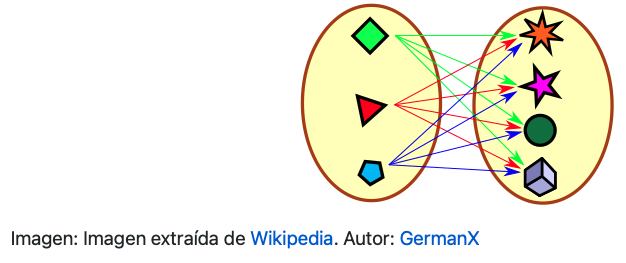

**Ejemplo**: Obtener el producto cartesiano de las tablas producto y fabricante.
```
SELECT *
FROM producto, fabricante;
```


## <font color='157699'> **4.1.2 Composiciones internas (Intersección)** </font>
La intersección de dos conjuntos es una operación que resulta en otro conjunto que contiene sólo los elementos comunes que existen en ambos conjuntos.

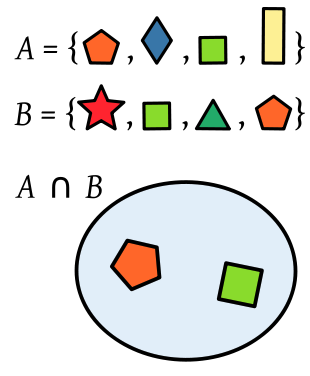

Para poder realizar una operación de intersección entre las dos tablas debemos utilizar la cláusula WHERE para indicar la columna con la que queremos relacionar las dos tablas.

**Ejemplo**: Devuelve una lista con el nombre del producto, precio y nombre de fabricante de todos los productos de la base de datos.
```
SELECT producto.nombre, producto.precio, fabricante.nombre
FROM producto, fabricante
WHERE producto.id_fabricante = fabricante.id ;
```


## <font color='157699'> **4.2 Consultas multitabla SQL2** </font>

## <font color='157699'> **4.2.1 Composiciones cruzadas (Producto cartesiano)** </font>
Se usa la función CROSS JOIN

**Ejemplo**: Obtener el producto cartesiano de las tablas producto y fabricante.
```
SELECT *
FROM producto CROSS JOIN fabricante;
```


## <font color='157699'> **4.2.2 Composiciones internas (intersección)** </font>
Se usan las funciones INNER JOIN o JOIN, NATURAL JOIN

**Ejemplo**: Devuelve una lista con el nombre del producto, precio y nombre de fabricante de todos los productos de la base de datos.
```
SELECT producto.nombre, producto.precio, fabricante.nombre
FROM producto INNER JOIN fabricante
ON producto.id_fabricante = fabricante.id ;
```
También se puede usar la función JOIN en lugar de INNER JOIN
```
SELECT producto.nombre, producto.precio, fabricante.nombre
FROM producto JOIN fabricante
ON producto.id_fabricante = fabricante.id ;
```

NOTAS:
1.   Cuando queremos realizar una composición interna entre dos tablas y las columnas que queremos relacionar tienen el mismo nombre en ambas tablas podemos utilizar la cláusula USING.

2.   Sólo deberíamos utilizar una composición de tipo NATURAL JOIN cuando estemos seguros que los nombres de las columnas sobre las que quiero relacionar las dos tablas se llaman igual en las dos tablas. Lo normal es que no suelan tener el mismo nombre y que debamos usar una composición de tipo INNER JOIN.

## <font color='157699'> **4.2.3 Composiciones externas** </font>
Se usan las funciones LEFT OUTER JOIN, RIGHT OUTER JOIN, FULL OUTER JOIN, NATURAL LEFT OUTER JOIN y NATURAL RIGHT OUTER JOIN.

**Ejemplo**: Devuelve un listado de todos los fabricantes que existen en la base de datos, junto con los productos que tiene cada uno de ellos. El listado deberá mostrar también aquellos fabricantes que no tienen productos asociados.
```
SELECT fabricante.nombre, producto.nombre
FROM fabricante LEFT JOIN producto
ON producto.id_fabricante = fabricante.id;
```
**Ejemplo**: Devuelve un listado donde sólo aparezcan aquellos fabricantes que no tienen ningún producto asociado.
```
SELECT fabricante.nombre, producto.nombre
FROM fabricante LEFT JOIN producto
ON producto.id_fabricante = fabricante.id
WHERE producto.nombre IS NULL;
```


## <font color='157699'> **4.3 Consultas resumen** </font>


## <font color='157699'> **4.3.1 Funciones de agregación** </font>
Estas funciones realizan una operación específica sobre todas las filas de un grupo. Las funciones más comunes son:

1.   MAX(expr): Valor máximo del grupo.
2.   MIN(expr): Valor mínimo del grupo.
3.   AVG(expr): Valor medio del grupo.
4.   SUM(expr): Suma de todos los valores del grupo.
5.   COUNT(*): Número de filas que tiene el resultado de la consulta.
6.   COUNT(columna): Número de valores no nulos que hay en esa columna.

**Ejemplo**: Calcula el número total de productos que hay en la tabla productos.
```
SELECT COUNT(distinct nombre)
FROM producto;
```

**Ejemplo**: Lista el nombre y el precio del producto más caro.
```
SELECT nombre, MAX(precio)
FROM producto;
```

**Ejemplo**:  Calcula la media del precio de todos los productos del fabricante Asus.
```
SELECT AVG(producto.precio), fabricante.nombre
FROM producto, fabricante
WHERE producto.id_fabricante = fabricante.id
AND fabricante.nombre = 'Asus';
```

## <font color='157699'> **4.3.2 Agrupamiento de filas (GROUP BY)** </font>
La cláusula GROUP BY nos permite crear grupos de filas que tienen los mismos valores en las columnas por las que se desea agrupar.

**Ejemplo**: Muestra el número total de productos que tiene cada uno de los fabricantes. El listado también debe incluir los fabricantes que no tienen ningún producto. El resultado mostrará dos columnas, una con el nombre del fabricante y otra con el número de productos que tiene. Ordene el resultado descendentemente por el número de productos.
```
SELECT fabricante.nombre, COUNT(producto.id_fabricante)
FROM fabricante LEFT JOIN producto
ON producto.id_fabricante = fabricante.id
GROUP BY fabricante.nombre
ORDER BY COUNT(producto.id_fabricante) desc;
```

# <font color='056938'> **5. Subconsultas** </font>
---

## <font color='157699'> **5.1 Subconsultas en la cláusula WHERE** </font>
La cláusula GROUP BY nos permite crear grupos de filas que tienen los mismos valores en las columnas por las que se desea agrupar.

**Ejemplo**: Devuelve todos los productos del fabricante Lenovo.
```
SELECT producto.nombre, fabricante.nombre
FROM producto, fabricante
WHERE producto.id_fabricante = fabricante.id
AND fabricante.nombre = 'Lenovo';
```
NOTA: En este caso sólo hay un nivel de anidamiento entre consultas pero pueden existir varios niveles de anidamiento.

**Ejemplo**: Devuelve todos los datos de los productos que tienen el mismo precio que el producto más caro del fabricante Lenovo.
```
SELECT *
FROM producto
WHERE producto.precio =
	(SELECT producto.precio
   FROM producto, fabricante
	 WHERE producto.id_fabricante = fabricante.id
   AND fabricante.nombre = 'Lenovo'
	 ORDER BY producto.precio DESC limit 0,1);
```


## <font color='157699'> **5.3 Subconsultas en la cláusula HAVING** </font>

**Ejemplo**: Devuelve un listado con todos los nombres de los fabricantes que tienen el mismo número de productos que el fabricante Lenovo.
```
SELECT fabricante.nombre, COUNT(producto.Id_fabricante)
FROM fabricante INNER JOIN producto
ON fabricante.Id = producto.Id_fabricante
GROUP BY fabricante.Id
HAVING COUNT(producto.Id_fabricante) >= (
    SELECT COUNT(producto.Id_fabricante)
    FROM fabricante INNER JOIN producto
    ON fabricante.Id = producto.Id_fabricante
    WHERE fabricante.nombre = 'Lenovo');
```

## <font color='157699'> **5.4 Subconsultas CON EXISTS Y NOT EXISTS** </font>

**Ejemplo**: Devuelve los nombres de los fabricantes que tienen productos asociados.
```
SELECT nombre
FROM fabricante
WHERE EXISTS (SELECT id_fabricante
             FROM producto
             WHERE fabricante.id = producto.id_fabricante);
```

**Ejemplo**: Devuelve los nombres de los fabricantes que no tienen productos asociados.
```
SELECT nombre
FROM fabricante
WHERE NOT EXISTS (SELECT id_fabricante
                  FROM producto
                  WHERE fabricante.id = producto.id_fabricante);
```

## <font color='157699'> **5.5 Subconsultas con IN y NOT IN** </font>

**Ejemplo**: Devuelve los nombres de los fabricantes que tienen productos asociados.
```
SELECT nombre
FROM fabricante
WHERE id IN (SELECT id_fabricante
             FROM producto);
```

**Ejemplo**: Devuelve los nombres de los fabricantes que no tienen productos asociados.
```
SELECT nombre
FROM fabricante
WHERE id NOT IN (SELECT id_fabricante
                FROM producto);

```

# <font color='056938'> **6. Referencias** </font>
---
Sánchez Hernández, J.J. (2024). Bases de datos. https://josejuansanchez.org/bd/.